# CelebA-HQ 256x256: Preprocessing and EDA



## 1. Setup
Mount Google Drive and create the project folders.

In [1]:
# Mount Google Drive and create the project folder structure.
# BASE is reused by every later cell. splits_clean/ will hold the final train/val/test lists (section 6).
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = '/content/drive/MyDrive/FYP_FaceCompletion'
for d in ['', '/splits_clean', '/code', '/results']:
    os.makedirs(BASE + d, exist_ok=True)
print("ready:", BASE)

Mounted at /content/drive
ready: /content/drive/MyDrive/FYP_FaceCompletion


## 2. Download dataset

In [2]:

# Dataset cache / restore configuration
import os
import shutil
import zipfile

!pip -q install datasets

DATA_ROOT = "/content/celebahq256"
OUT = f"{DATA_ROOT}/all"
DRIVE_ZIP = f"{BASE}/celebahq256.zip"

EXPECTED_COUNT = 30000

def count_pngs(folder):
    if not os.path.isdir(folder):
        return 0
    return sum(
        f.lower().endswith(".png")
        for f in os.listdir(folder)
        if os.path.isfile(os.path.join(folder, f))
    )

local_count = count_pngs(OUT)

if local_count == EXPECTED_COUNT:
    DATASET_ACTION = "skip"
    print("Full dataset already exists in Colab. Reusing it.")

elif os.path.isfile(DRIVE_ZIP):
    print("Restoring dataset from Google Drive ZIP...")

    if os.path.isdir(OUT):
        shutil.rmtree(OUT)

    os.makedirs(DATA_ROOT, exist_ok=True)

    with zipfile.ZipFile(DRIVE_ZIP, "r") as z:
        z.extractall(DATA_ROOT)

    restored_count = count_pngs(OUT)
    assert restored_count == EXPECTED_COUNT, (
        f"Expected {EXPECTED_COUNT} images, found {restored_count}"
    )

    DATASET_ACTION = "skip"
    print(f"Restored {restored_count} images successfully.")

else:
    print("No complete local dataset or Drive ZIP found.")
    print("Downloading dataset from Hugging Face...")

    from datasets import load_dataset

    ds = load_dataset(
        "eurecom-ds/celeba-hq-256",
        split="train"
    )

    assert len(ds) == EXPECTED_COUNT, (
        f"Expected {EXPECTED_COUNT} samples, found {len(ds)}"
    )

    DATASET_ACTION = "download"


Restoring dataset from Google Drive ZIP...
Restored 30000 images successfully.


## 3. Export images as PNG

In [3]:
# Find the image column, then save every image as a numbered PNG (00000.png ... 29999.png) in OUT.
# All later steps read their images from OUT.

from tqdm import tqdm

if DATASET_ACTION == "download":
    img_cols = [
        k for k, v in ds.features.items()
        if v.__class__.__name__ == "Image"
    ]

    col = img_cols[0]
    os.makedirs(OUT, exist_ok=True)

    for i in tqdm(range(len(ds)), desc="Exporting PNGs"):
        ds[i][col].convert("RGB").save(
            f"{OUT}/{i:05d}.png"
        )

    print("PNG export complete.")

else:
    print("Download/export skipped. Using existing images.")

print("Images available:", count_pngs(OUT))

Download/export skipped. Using existing images.
Images available: 30000


## 4. Checking Files



In [4]:
#  confirm every file opens, collect sizes/modes and count exact duplicates via MD5.
# (The full EDA below goes into much more detail.)
import glob, hashlib
from PIL import Image

files = sorted(glob.glob(OUT + '/*.png'))
print("count:", len(files))

bad, dups, seen, shapes = [], [], {}, set()
for f in tqdm(files):
    try:
        im = Image.open(f); im.load()
        shapes.add((im.size, im.mode))
        h = hashlib.md5(im.tobytes()).hexdigest()
        if h in seen: dups.append((f, seen[h]))
        else: seen[h] = f
    except Exception as e:
        bad.append((f, str(e)))
print()
print("sizes/modes:", shapes)
print("corrupt:", len(bad), "| duplicates:", len(dups))

count: 30000


100%|██████████| 30000/30000 [02:02<00:00, 243.93it/s]


sizes/modes: {((256, 256), 'RGB')}
corrupt: 0 | duplicates: 27


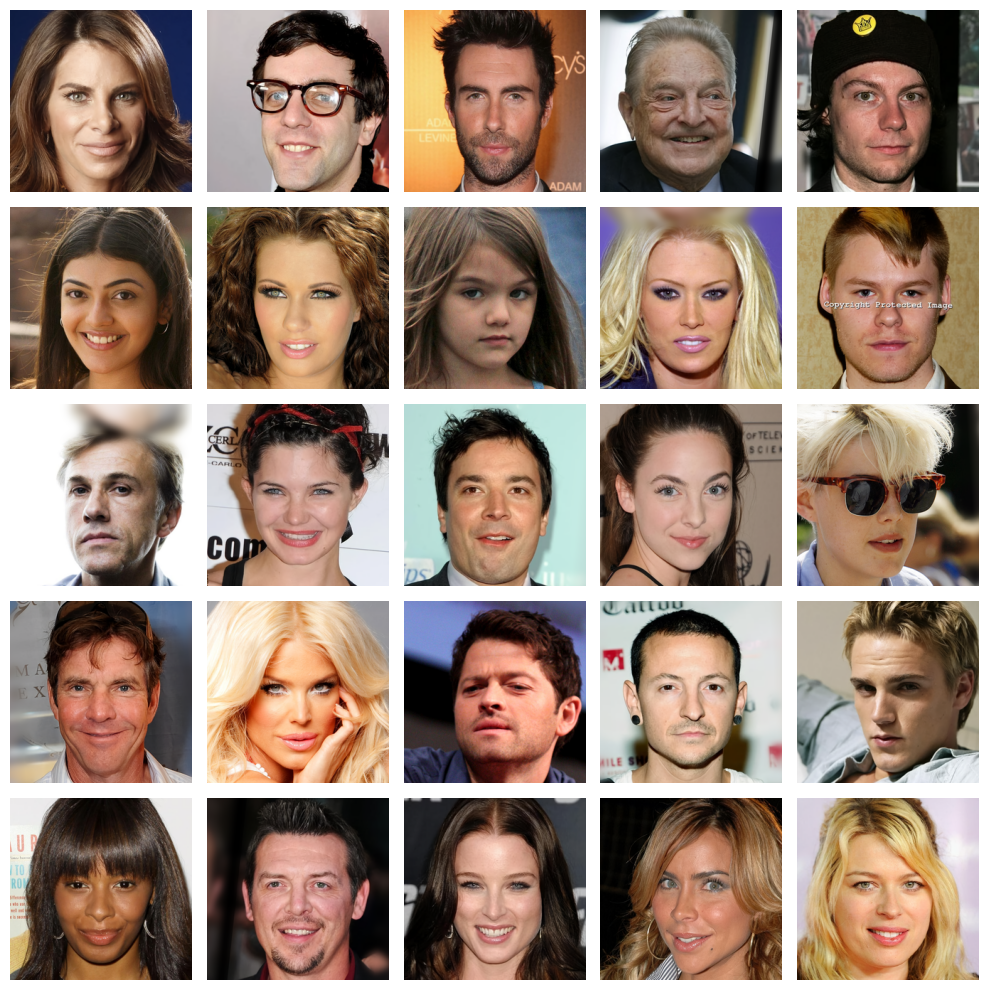

In [5]:
# Show 25 random images as a quick visual check.
import random, matplotlib.pyplot as plt
sample = random.sample(files, 25)
fig, axs = plt.subplots(5, 5, figsize=(10, 10))
for ax, f in zip(axs.ravel(), sample):
    ax.imshow(Image.open(f)); ax.axis('off')
plt.tight_layout(); plt.show()

## 5. EDA
The EDA only inspects the data.

### 5.1 Configuration and imports

In [6]:
# EDA configuration: paths, expected values and the near-duplicate threshold.
import os

IMG_DIR = OUT
OUT_DIR = f'{BASE}/eda'
EXPECTED_COUNT = 30000
EXPECTED_SIZE = (256, 256)
SEED = 42
# Max Hamming distance (out of 64 bits) for two images to count as near-duplicates; lower = stricter
NEAR_DUP_THRESH = 4

assert os.path.isdir(IMG_DIR), f"{IMG_DIR} not found. Run the unzip step first."
os.makedirs(OUT_DIR, exist_ok=True)
print("Image folder:", IMG_DIR)
print("Report folder:", OUT_DIR)
print("Config ready.")

Image folder: /content/celebahq256/all
Report folder: /content/drive/MyDrive/FYP_FaceCompletion/eda
Config ready.


In [7]:
# Imports and plot settings for the EDA.
import glob, hashlib, random, json, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})
print("Imports done.")

Imports done.


### 5.2 Scan all images

In [8]:
# Single pass over all images: detect unreadable files and collect per-image statistics, histograms,
# thumbnails (for PCA) and hashes (for duplicate detection).
EXTS = ('.png', '.jpg', '.jpeg', '.bmp', '.webp', '.tif', '.tiff')
all_files = sorted(f for f in os.listdir(IMG_DIR) if os.path.isfile(os.path.join(IMG_DIR, f)))
img_files = [f for f in all_files if f.lower().endswith(EXTS)]
other_files = [f for f in all_files if not f.lower().endswith(EXTS)]
N = len(img_files)
print(f"Total files in folder: {len(all_files)} | image files: {N} | other files: {len(other_files)}")
assert N > 0, "No images found. Check IMG_DIR."

H, W = EXPECTED_SIZE
sum_img = np.zeros((H, W, 3), np.float64)
sumsq_img = np.zeros((H, W, 3), np.float64)
n_acc = 0
hist = np.zeros((3, 256), np.int64)
thumbs = np.zeros((N, 32, 32, 3), np.uint8)
dhash = np.zeros((N, 64), bool)
records = []

# Loop over every image file
for k, f in enumerate(tqdm(img_files, desc="scanning")):
    p = os.path.join(IMG_DIR, f)
    rec = dict(name=f, bytes=os.path.getsize(p), ok=False, error='')
    try:
        with Image.open(p) as im:
            rec['format'] = im.format
            rec['mode'] = im.mode
            # load() forces a full decode, so truncated or corrupted files raise an error here
            im.load()
            rec['width'], rec['height'] = im.size
            arr = np.asarray(im.convert('RGB'))
    except Exception as e:
        rec['error'] = f"{type(e).__name__}: {e}"[:150]
        records.append(rec)
        continue

    # Per-channel statistics and the global histogram
    rec['ok'] = True
    for c, ch in enumerate('RGB'):
        a = arr[..., c]
        rec[f'mean_{ch}'] = float(a.mean())
        rec[f'std_{ch}'] = float(a.std())
        rec[f'min_{ch}'] = int(a.min())
        rec[f'max_{ch}'] = int(a.max())
        hist[c] += np.bincount(a.ravel(), minlength=256)

    # Brightness, contrast, sharpness (Laplacian variance) and grayscale detection
    gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
    rec['brightness'] = float(gray.mean())
    rec['contrast'] = float(gray.std())
    rec['sharpness'] = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    d1 = np.abs(arr[..., 0].astype(np.int16) - arr[..., 1]).mean()
    d2 = np.abs(arr[..., 1].astype(np.int16) - arr[..., 2]).mean()
    rec['chan_diff'] = float((d1 + d2) / 2)
    rec['is_gray'] = bool(rec['chan_diff'] < 1.0)
    # MD5 of the pixel bytes: identical hashes mean exact duplicates
    rec['md5'] = hashlib.md5(arr.tobytes()).hexdigest()

    # 32x32 thumbnail for the PCA plot
    thumbs[k] = cv2.resize(arr, (32, 32), interpolation=cv2.INTER_AREA)
    # 64-bit difference hash (dHash) for near-duplicate search
    small = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    dhash[k] = (small[:, 1:] > small[:, :-1]).ravel()

    # Running sums for the mean and std images
    if arr.shape == (H, W, 3):
        x = arr.astype(np.float64)
        sum_img += x
        sumsq_img += x * x
        n_acc += 1
    records.append(rec)

df = pd.DataFrame(records)
df.to_csv(os.path.join(OUT_DIR, 'image_features.csv'), index=False)
print(f"\nScan complete. Readable: {int(df.ok.sum())} | unreadable/corrupted: {int((~df.ok).sum())}")
print("Saved: image_features.csv")

Total files in folder: 30000 | image files: 30000 | other files: 0


scanning:   0%|          | 0/30000 [00:00<?, ?it/s]


Scan complete. Readable: 30000 | unreadable/corrupted: 0
Saved: image_features.csv


### 5.3 Dataset overview (missing, corrupted, unreadable)

Total files in folder             30000
Image files                       30000
Non-image files                       0
Readable images                   30000
Corrupted / unreadable                0
Zero-byte files                       0
Numbering gaps (missing files)        0
Images with unexpected size           0
NaN in feature table                  0 

Image sizes (width x height):
  width  height  count
   256     256  30000 

Original colour modes:
 mode
RGB    30000 

File formats:
 format
PNG    30000 

File size (KB) summary:
 count    30000.0
mean       101.1
std         12.5
min         44.3
25%         92.6
50%        100.9
75%        109.5
max        154.1


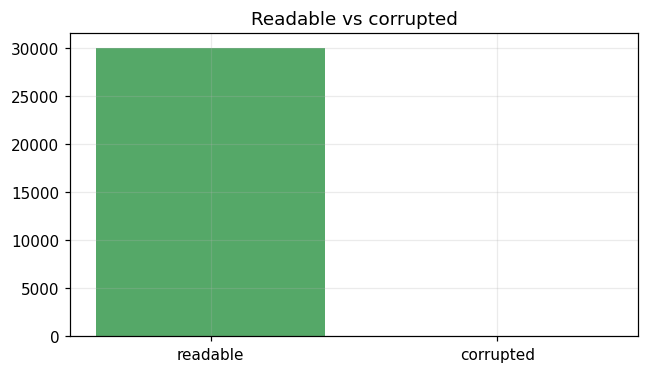


--- Overview verdict ---
PASS  Image count matches expected
PASS  No corrupted or unreadable files
PASS  No zero-byte files
PASS  No gaps in file numbering
PASS  All images have the expected size
PASS  All images are originally RGB
PASS  No non-image files in folder


In [9]:
# Overview: missing, corrupted and unreadable files, image sizes, colour modes and a PASS/CHECK verdict.
ok_df = df[df.ok].copy()
ok_df[['width', 'height']] = ok_df[['width', 'height']].astype(int)
bad_df = df[~df.ok].copy()

# Missing files: gaps in the numbering 00000 ... 29999
stems = [os.path.splitext(f)[0] for f in img_files]
missing_idx = []
if all(s.isdigit() for s in stems):
    nums = sorted(int(s) for s in stems)
    missing_idx = sorted(set(range(nums[0], nums[-1] + 1)) - set(nums))

feat_cols = [c for c in ok_df.columns if c.startswith(('mean_', 'std_', 'min_', 'max_'))] + ['brightness', 'contrast', 'sharpness']
n_nan = int(ok_df[feat_cols].isna().sum().sum())

sizes = ok_df.groupby(['width', 'height']).size().rename('count').reset_index()
modes = ok_df['mode'].value_counts()
fmts = ok_df['format'].value_counts()
wrong_size = int(((ok_df.width != W) | (ok_df.height != H)).sum())
zero_byte = int((df.bytes == 0).sum())

summary = pd.Series({
    'Total files in folder': len(all_files),
    'Image files': N,
    'Non-image files': len(other_files),
    'Readable images': int(df.ok.sum()),
    'Corrupted / unreadable': int((~df.ok).sum()),
    'Zero-byte files': zero_byte,
    'Numbering gaps (missing files)': len(missing_idx),
    'Images with unexpected size': wrong_size,
    'NaN in feature table': n_nan,
})
print(summary.to_string(), "\n")
print("Image sizes (width x height):\n", sizes.to_string(index=False), "\n")
print("Original colour modes:\n", modes.to_string(), "\n")
print("File formats:\n", fmts.to_string(), "\n")
print("File size (KB) summary:\n", (ok_df.bytes / 1024).describe().round(1).to_string())

if len(bad_df):
    print("\nCorrupted / unreadable files:")
    print(bad_df[['name', 'bytes', 'error']].to_string(index=False))
    bad_df.to_csv(os.path.join(OUT_DIR, 'bad_files.csv'), index=False)
if other_files:
    print("\nNon-image files in folder:", other_files[:20])
if missing_idx:
    print("\nMissing numbers (first 20):", missing_idx[:20])


fig, ax = plt.subplots(figsize=(6, 3.5))

ax.bar(
    ['readable', 'corrupted'],
    [int(df.ok.sum()), int((~df.ok).sum())],
    color=['#55A868', '#C44E52']
)

ax.set_title('Readable vs corrupted')
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, '1_overview.png'))
plt.show()


# Final PASS/CHECK verdict
checks = [
    ("Image count matches expected", N == EXPECTED_COUNT),
    ("No corrupted or unreadable files", len(bad_df) == 0),
    ("No zero-byte files", zero_byte == 0),
    ("No gaps in file numbering", len(missing_idx) == 0),
    ("All images have the expected size", wrong_size == 0),
    ("All images are originally RGB", set(modes.index) <= {'RGB'}),
    ("No non-image files in folder", len(other_files) == 0),
]
print("\n--- Overview verdict ---")
for t, passed in checks:
    print(("PASS  " if passed else "CHECK ") + t)

### 5.4 Visual inspection of 30 random images

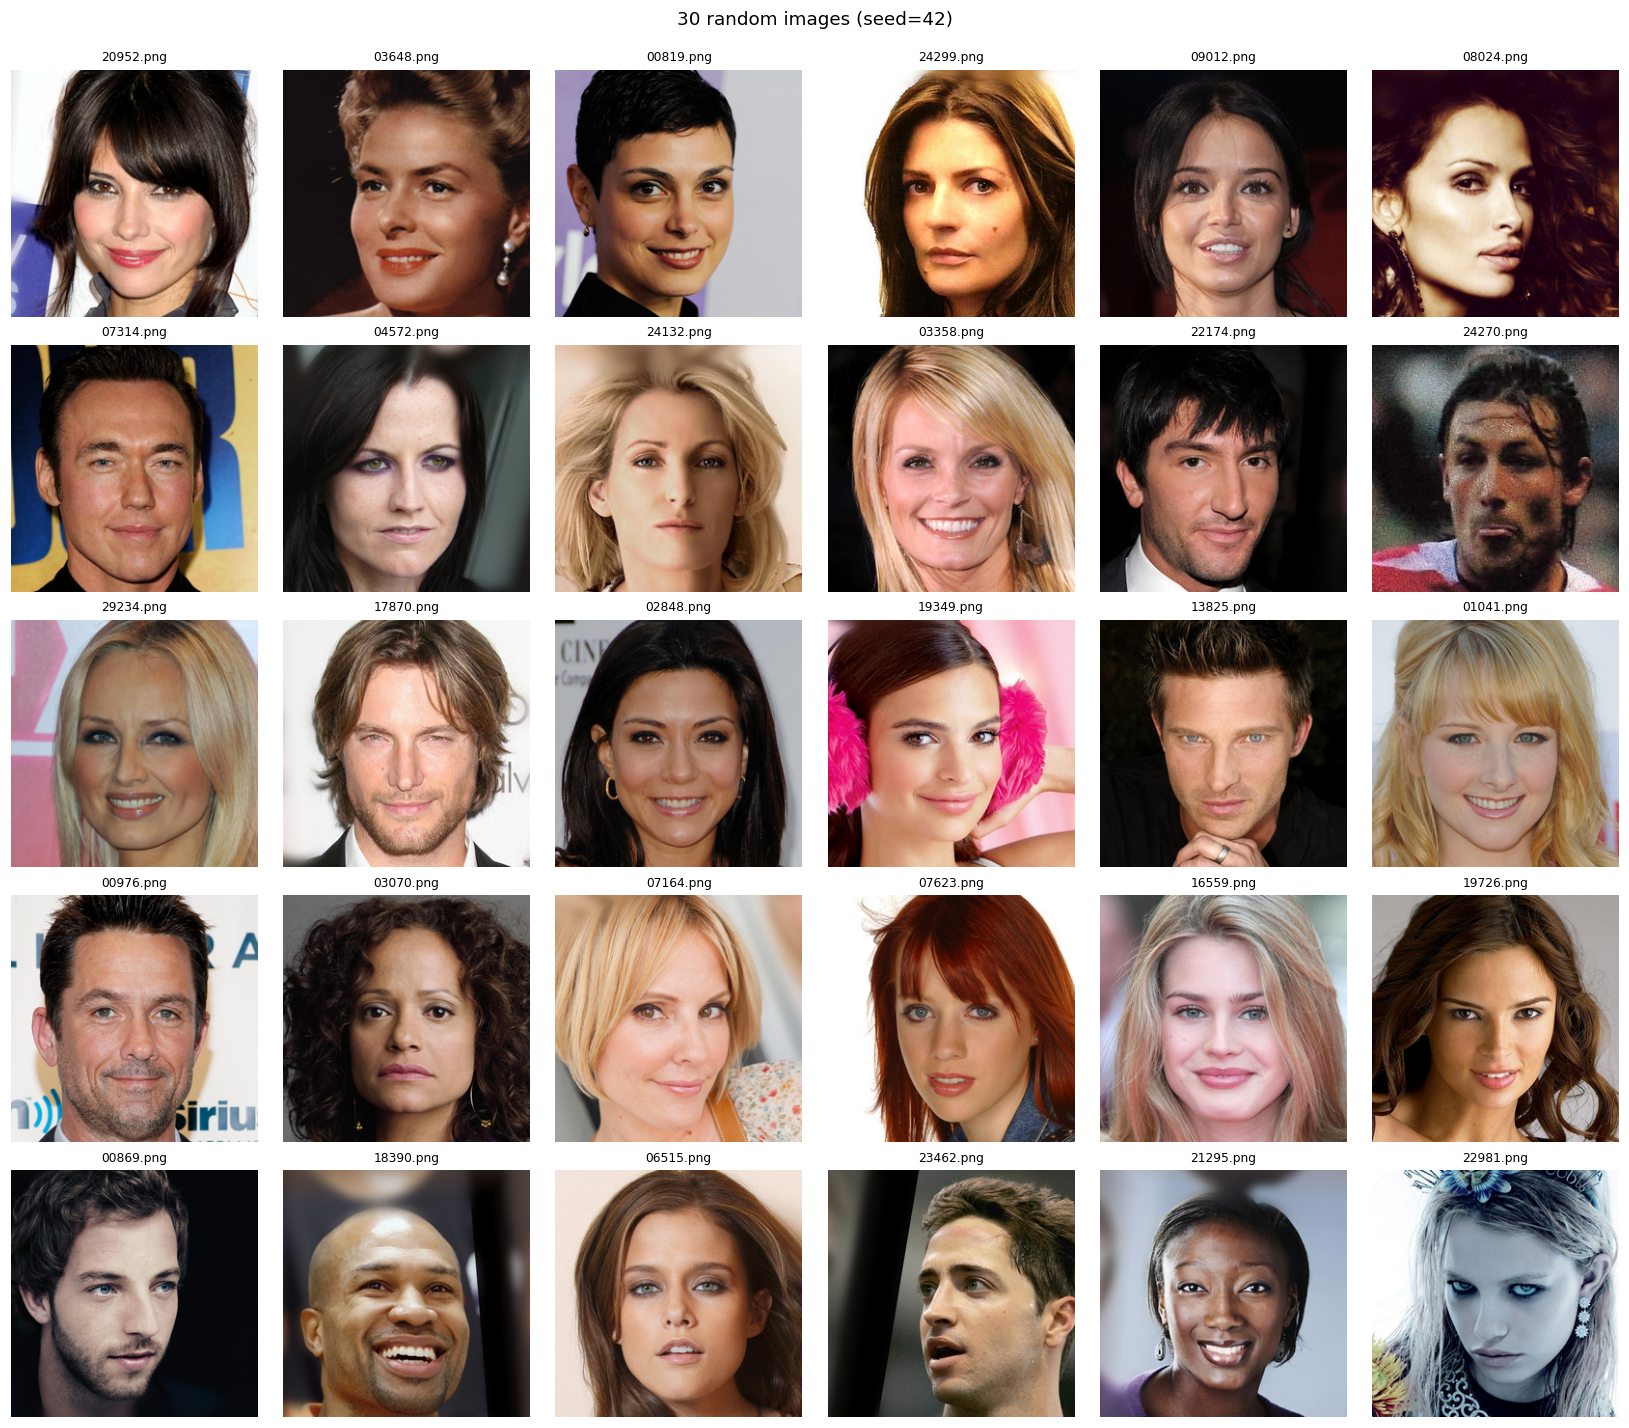

Displayed 30 random images. Saved: 2_random_30.png


In [10]:
# Visual inspection: 30 random images (fixed seed, so the grid is reproducible).
rng = random.Random(SEED)
pick = rng.sample(list(ok_df['name']), min(30, len(ok_df)))

fig, axs = plt.subplots(5, 6, figsize=(15, 13))
for ax in axs.ravel():
    ax.axis('off')
for ax, f in zip(axs.ravel(), pick):
    ax.imshow(Image.open(os.path.join(IMG_DIR, f)).convert('RGB'))
    ax.set_title(f, fontsize=8)
plt.suptitle(f"30 random images (seed={SEED})", y=0.995)
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, '2_random_30.png'))
plt.show()
print(f"Displayed {len(pick)} random images. Saved: 2_random_30.png")

### 5.5 Pixel intensity distribution (RGB)

Pixel statistics over the whole dataset (per channel):
         min  max    mean  median    std  pct_pixels_eq_0  pct_pixels_eq_255
channel                                                                     
R          0  255  131.60     141  77.45            1.391              0.720
G          0  255  105.92     104  70.18            1.734              0.634
B          0  255   92.19      82  68.89            2.249              0.666


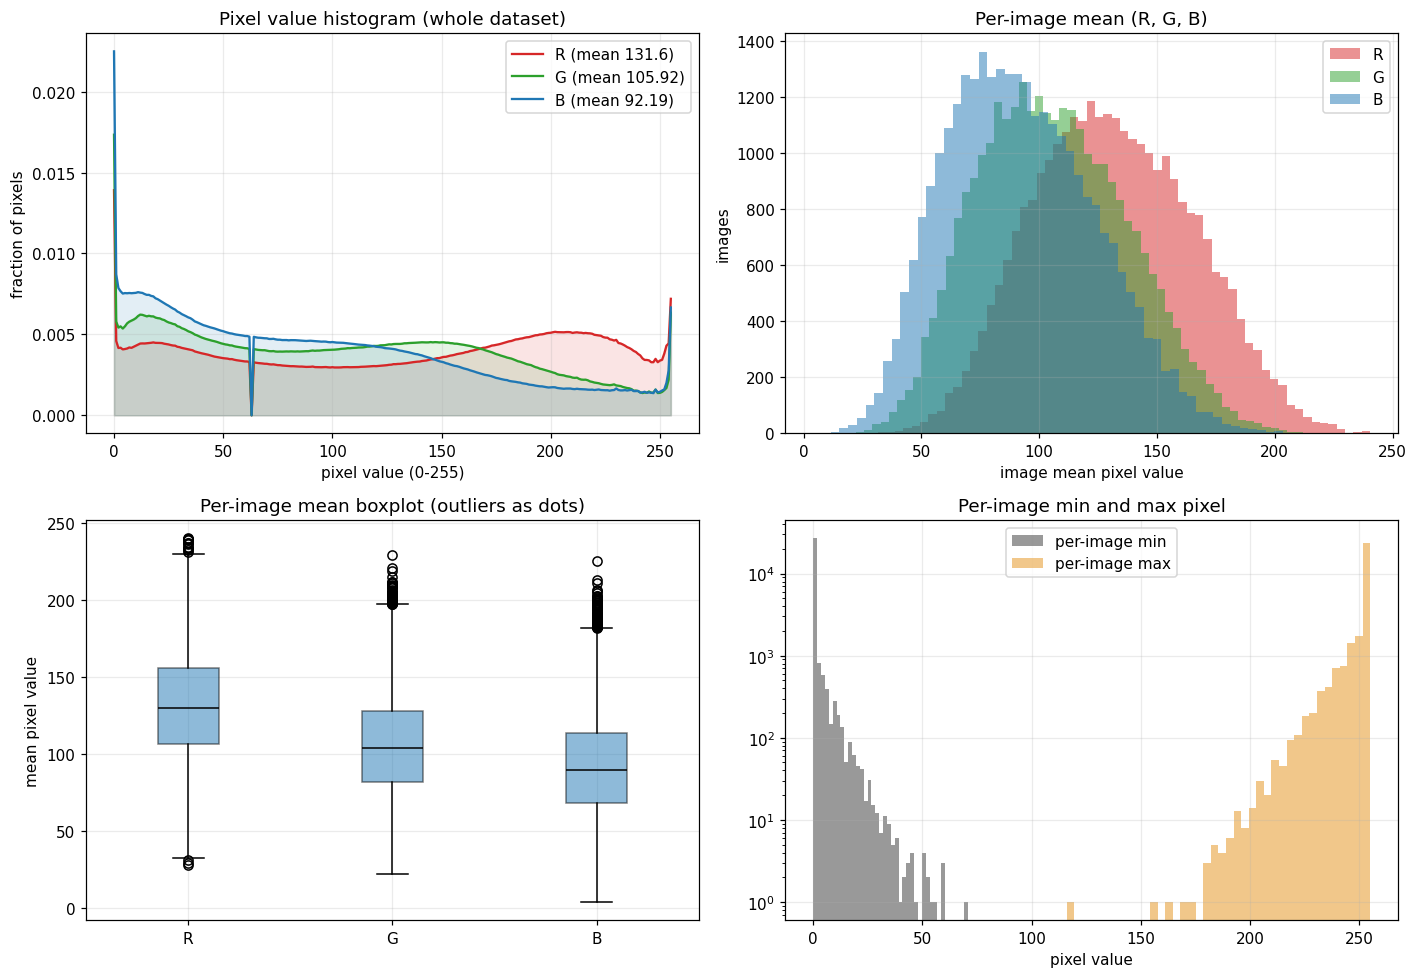

Images containing a pure black pixel (0): 88.3%
Images containing a pure white pixel (255): 68.8%
Per-image mean (average of R, G, B) ranges from 24.2 to 230.7


In [11]:
# RGB pixel value distribution: min, max, mean, median and std per channel, plus histograms.
vals = np.arange(256)
rows = []
for c, ch in enumerate('RGB'):
    h = hist[c]
    tot = h.sum()
    mean = (vals * h).sum() / tot
    std = np.sqrt((((vals - mean) ** 2) * h).sum() / tot)
    nz = np.nonzero(h)[0]
    med = int(np.searchsorted(np.cumsum(h), tot / 2))
    rows.append(dict(channel=ch, min=int(nz[0]), max=int(nz[-1]), mean=round(mean, 2), median=med, std=round(std, 2),
                     pct_pixels_eq_0=round(100 * h[0] / tot, 3), pct_pixels_eq_255=round(100 * h[255] / tot, 3)))
chan_stats = pd.DataFrame(rows).set_index('channel')
print("Pixel statistics over the whole dataset (per channel):")
print(chan_stats.to_string())
chan_stats.to_csv(os.path.join(OUT_DIR, 'channel_stats.csv'))

col = {'R': '#d62728', 'G': '#2ca02c', 'B': '#1f77b4'}
fig, axs = plt.subplots(2, 2, figsize=(13, 9))

for c, ch in enumerate('RGB'):
    axs[0, 0].plot(vals, hist[c] / hist[c].sum(), color=col[ch], label=f"{ch} (mean {chan_stats.loc[ch, 'mean']})")
    axs[0, 0].fill_between(vals, hist[c] / hist[c].sum(), color=col[ch], alpha=.12)
axs[0, 0].set_title('Pixel value histogram (whole dataset)')
axs[0, 0].set_xlabel('pixel value (0-255)')
axs[0, 0].set_ylabel('fraction of pixels')
axs[0, 0].legend()

for ch in 'RGB':
    axs[0, 1].hist(ok_df[f'mean_{ch}'], bins=60, alpha=.5, color=col[ch], label=ch)
axs[0, 1].set_title('Per-image mean (R, G, B)')
axs[0, 1].set_xlabel('image mean pixel value')
axs[0, 1].set_ylabel('images')
axs[0, 1].legend()

axs[1, 0].boxplot([ok_df[f'mean_{ch}'] for ch in 'RGB'], patch_artist=True,
                  boxprops=dict(alpha=.5), medianprops=dict(color='k'))
axs[1, 0].set_xticklabels(list('RGB'))
axs[1, 0].set_title('Per-image mean boxplot (outliers as dots)')
axs[1, 0].set_ylabel('mean pixel value')

axs[1, 1].hist(ok_df[['min_R', 'min_G', 'min_B']].min(axis=1), bins=40, alpha=.6, label='per-image min', color='#555')
axs[1, 1].hist(ok_df[['max_R', 'max_G', 'max_B']].max(axis=1), bins=40, alpha=.6, label='per-image max', color='#e8a33d')
axs[1, 1].set_title('Per-image min and max pixel')
axs[1, 1].set_xlabel('pixel value')
axs[1, 1].set_yscale('log')
axs[1, 1].legend()
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, '3a_pixel_distribution.png'))
plt.show()

img_min = ok_df[['min_R', 'min_G', 'min_B']].min(axis=1)
img_max = ok_df[['max_R', 'max_G', 'max_B']].max(axis=1)
img_mean = ok_df[['mean_R', 'mean_G', 'mean_B']].mean(axis=1)
print(f"Images containing a pure black pixel (0): {(img_min == 0).mean() * 100:.1f}%")
print(f"Images containing a pure white pixel (255): {(img_max == 255).mean() * 100:.1f}%")
print(f"Per-image mean (average of R, G, B) ranges from {img_mean.min():.1f} to {img_mean.max():.1f}")

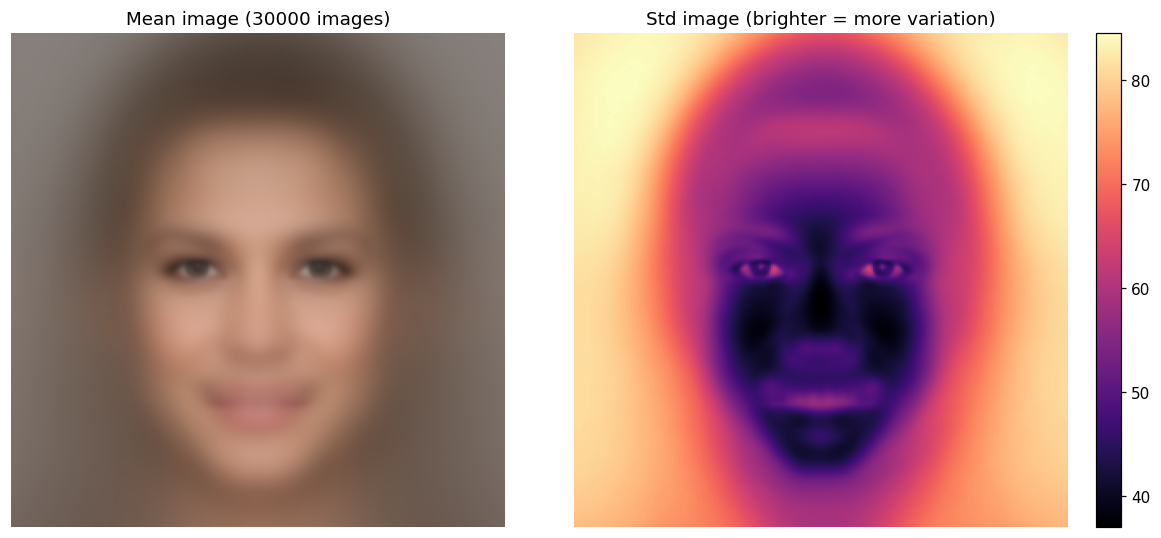

Mean and std images computed from 30000 images. Saved: 3b_mean_std_image.png


In [12]:
# Mean image and std image over the whole dataset (shows how well faces are aligned and centred).
mean_img = sum_img / n_acc
std_img = np.sqrt(np.maximum(sumsq_img / n_acc - mean_img ** 2, 0))

fig, axs = plt.subplots(1, 2, figsize=(11, 5))
axs[0].imshow(mean_img.astype(np.uint8))
axs[0].set_title(f'Mean image ({n_acc} images)')
axs[0].axis('off')
im = axs[1].imshow(std_img.mean(axis=2), cmap='magma')
axs[1].set_title('Std image (brighter = more variation)')
axs[1].axis('off')
plt.colorbar(im, ax=axs[1], fraction=.046)
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, '3b_mean_std_image.png'))
plt.show()
print(f"Mean and std images computed from {n_acc} images. Saved: 3b_mean_std_image.png")

### 5.6 Image diversity

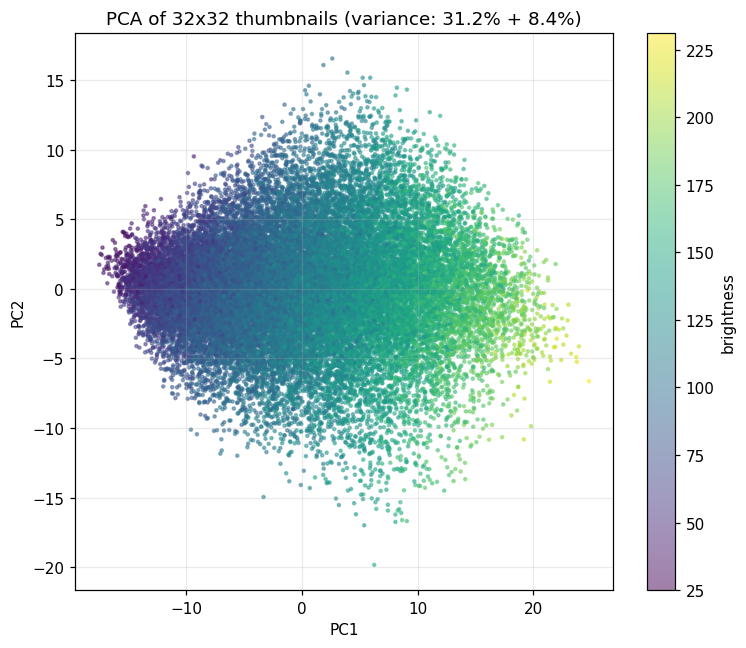

Saved: 3c_diversity_hist.png, 3d_pca.png


In [13]:

# PCA of 32x32 thumbnails: each dot is one image, nearby dots look alike
from sklearn.decomposition import PCA
ok_idx = np.where(df.ok.values)[0]
X = thumbs[ok_idx].reshape(len(ok_idx), -1).astype(np.float32) / 255.0
pca = PCA(n_components=2, svd_solver='randomized', random_state=SEED)
Z = pca.fit_transform(X)
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(Z[:, 0], Z[:, 1], c=ok_df.brightness.values, s=4, alpha=.5, cmap='viridis')
plt.colorbar(sc, label='brightness')
ax.set_title(f'PCA of 32x32 thumbnails (variance: {pca.explained_variance_ratio_[0]*100:.1f}% + {pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, '3d_pca.png'))
plt.show()
print("Saved: 3c_diversity_hist.png, 3d_pca.png")

### 5.7 Duplicate images

In [14]:
# Duplicate detection.
# Exact duplicates: identical MD5 of the pixel data.
# Near duplicates: dHash Hamming distance <= NEAR_DUP_THRESH (candidates only, they need a visual check).
dup_mask = ok_df.duplicated('md5', keep=False)
exact = ok_df[dup_mask].sort_values('md5')
n_groups = exact.md5.nunique()
extra_copies = int(dup_mask.sum() - n_groups)
print(f"Exact duplicate groups: {n_groups} | extra copies that can be removed: {extra_copies}")
if len(exact):
    print(exact[['name', 'md5']].assign(md5=lambda d: d.md5.str[:10]).to_string(index=False))
    exact[['name', 'md5']].to_csv(os.path.join(OUT_DIR, 'exact_duplicates.csv'), index=False)

# Hamming distance between all pairs, computed in chunks with matrix multiplication
A = dhash[ok_idx].astype(np.float32)
B = 1.0 - A
pairs = []
CH = 500
for st in tqdm(range(0, len(ok_idx), CH), desc="near-duplicate search"):
    en = min(st + CH, len(ok_idx))
    ham = 64 - (A[st:en] @ A.T + B[st:en] @ B.T)
    r, cidx = np.where(ham <= NEAR_DUP_THRESH)
    keep = (cidx > r + st)
    r, cidx = r[keep], cidx[keep]
    for i, j, h in zip(r + st, cidx, ham[r, cidx]):
        pairs.append((ok_idx[i], ok_idx[j], int(round(h))))
    if len(pairs) > 20000:
        print("Too many pairs found. Lower NEAR_DUP_THRESH and rerun.")
        break

pairs_df = pd.DataFrame(pairs, columns=['i', 'j', 'hamming'])
if len(pairs_df):
    pairs_df['name_a'] = df['name'].values[pairs_df.i]
    pairs_df['name_b'] = df['name'].values[pairs_df.j]
    pairs_df['same_pixels'] = df.md5.values[pairs_df.i] == df.md5.values[pairs_df.j]
near_only = pairs_df[~pairs_df.same_pixels] if len(pairs_df) else pairs_df
print(f"\nNear-duplicate candidate pairs (hamming <= {NEAR_DUP_THRESH}), excluding exact copies: {len(near_only)}")
if len(near_only):
    near_only[['name_a', 'name_b', 'hamming']].to_csv(os.path.join(OUT_DIR, 'near_duplicates.csv'), index=False)
    print(near_only[['name_a', 'name_b', 'hamming']].head(15).to_string(index=False))

Exact duplicate groups: 27 | extra copies that can be removed: 27
     name        md5
03329.png 036570b1b9
03330.png 036570b1b9
15506.png 0d6414ce5e
15507.png 0d6414ce5e
24646.png 1ccbb8d2df
24647.png 1ccbb8d2df
04445.png 2facf0fc41
04446.png 2facf0fc41
19199.png 33d1f4683b
19200.png 33d1f4683b
01679.png 35f7acc734
01680.png 35f7acc734
10262.png 38986c7351
10263.png 38986c7351
08406.png 450539b202
08405.png 450539b202
25190.png 490689a71d
25191.png 490689a71d
13826.png 4bd70ae724
13825.png 4bd70ae724
04101.png 5017c63b0e
04100.png 5017c63b0e
08976.png 533aa7e512
08975.png 533aa7e512
05773.png 5b8a14e4a8
05774.png 5b8a14e4a8
16814.png 637310c628
16813.png 637310c628
23489.png 69f44a7233
23490.png 69f44a7233
06770.png 7231dea470
06771.png 7231dea470
07562.png 799466606d
07561.png 799466606d
12885.png 9ecf80693e
12886.png 9ecf80693e
05797.png b6edbbe5e1
05796.png b6edbbe5e1
01757.png b82ef1f4d0
01756.png b82ef1f4d0
12445.png c63e217017
12444.png c63e217017
07384.png cd30c471a6
07385.png 

near-duplicate search:   0%|          | 0/60 [00:00<?, ?it/s]


Near-duplicate candidate pairs (hamming <= 4), excluding exact copies: 12066
   name_a    name_b  hamming
00003.png 03230.png        3
00004.png 21058.png        4
00025.png 04008.png        4
00038.png 04467.png        4
00038.png 15448.png        4
00039.png 23581.png        4
00042.png 10029.png        3
00050.png 08249.png        4
00055.png 09069.png        4
00066.png 13135.png        4
00068.png 00342.png        1
00074.png 00270.png        4
00074.png 01360.png        4
00074.png 01576.png        3
00074.png 17447.png        3


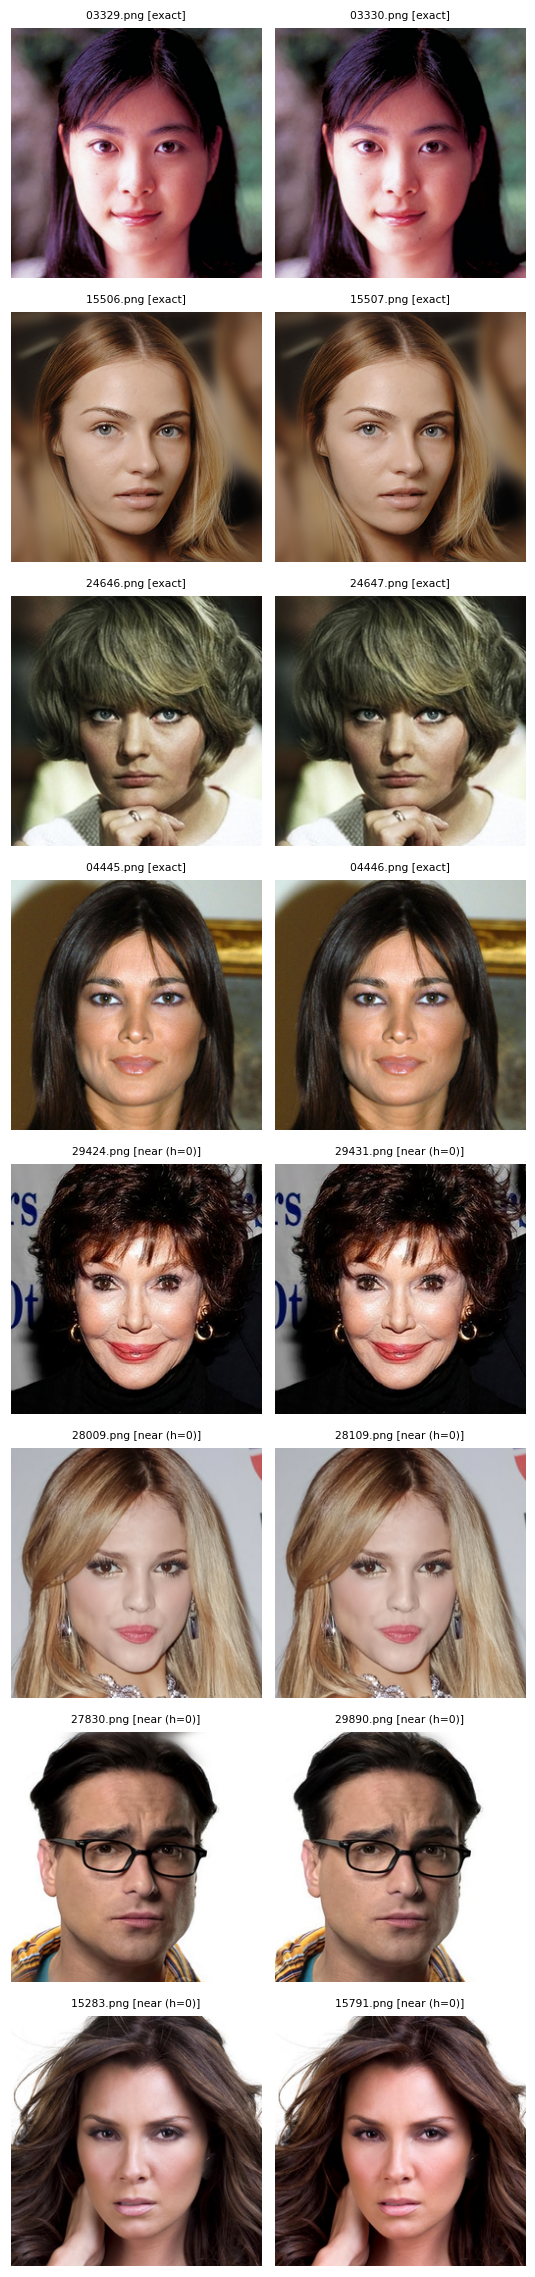

Displayed 8 duplicate pairs. Saved: 4_duplicates.png


In [15]:
# Show a few exact and near-duplicate pairs side by side.
dup_show = []
if len(exact):
    g = exact.groupby('md5')['name'].apply(list)
    dup_show += [(l[0], l[1], 'exact') for l in g.tolist()[:4]]
if len(near_only):
    dup_show += [(r.name_a, r.name_b, f'near (h={r.hamming})') for r in near_only.sort_values('hamming').head(8 - len(dup_show)).itertuples()]

if dup_show:
    fig, axs = plt.subplots(len(dup_show), 2, figsize=(5, 2.6 * len(dup_show)))
    axs = np.atleast_2d(axs)
    for r, (a, b2, tag) in enumerate(dup_show):
        for k, f in enumerate((a, b2)):
            axs[r, k].imshow(Image.open(os.path.join(IMG_DIR, f)).convert('RGB'))
            axs[r, k].axis('off')
            axs[r, k].set_title(f"{f} [{tag}]", fontsize=7)
    plt.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, '4_duplicates.png'))
    plt.show()
    print(f"Displayed {len(dup_show)} duplicate pairs. Saved: 4_duplicates.png")
else:
    print("No duplicate pairs found to display.")

### 5.8 EDA summary

In [16]:
# EDA summary: collect the key numbers into eda_summary.json.
report = {
    'images_in_folder': N,
    'expected': EXPECTED_COUNT,
    'readable': int(df.ok.sum()),
    'corrupted_or_unreadable': int((~df.ok).sum()),
    'zero_byte_files': zero_byte,
    'numbering_gaps': len(missing_idx),
    'wrong_size_images': wrong_size,
    'original_modes': modes.to_dict(),
    'grayscale_images': int(ok_df.is_gray.sum()),
    'channel_stats': chan_stats.to_dict(orient='index'),
    'exact_duplicate_groups': int(n_groups),
    'exact_duplicate_extra_copies': extra_copies,
    'near_duplicate_pairs': int(len(near_only)),
    'near_dup_threshold': NEAR_DUP_THRESH,
}
with open(os.path.join(OUT_DIR, 'eda_summary.json'), 'w') as fh:
    json.dump(report, fh, indent=2, default=str)

print(json.dumps(report, indent=2, default=str))
print("\nSaved files:", sorted(os.listdir(OUT_DIR)))

{
  "images_in_folder": 30000,
  "expected": 30000,
  "readable": 30000,
  "corrupted_or_unreadable": 0,
  "zero_byte_files": 0,
  "numbering_gaps": 0,
  "wrong_size_images": 0,
  "original_modes": {
    "RGB": 30000
  },
  "grayscale_images": 5,
  "channel_stats": {
    "R": {
      "min": 0,
      "max": 255,
      "mean": 131.6,
      "median": 141,
      "std": 77.45,
      "pct_pixels_eq_0": 1.391,
      "pct_pixels_eq_255": 0.72
    },
    "G": {
      "min": 0,
      "max": 255,
      "mean": 105.92,
      "median": 104,
      "std": 70.18,
      "pct_pixels_eq_0": 1.734,
      "pct_pixels_eq_255": 0.634
    },
    "B": {
      "min": 0,
      "max": 255,
      "mean": 92.19,
      "median": 82,
      "std": 68.89,
      "pct_pixels_eq_0": 2.249,
      "pct_pixels_eq_255": 0.666
    }
  },
  "exact_duplicate_groups": 27,
  "exact_duplicate_extra_copies": 27,
  "near_duplicate_pairs": 12066,
  "near_dup_threshold": 4
}

Saved files: ['1_overview.png', '2_random_30.png', '3a_pixel

## 6. Cleaning and train/val/test split
Exact duplicates and near-duplicates (Hamming distance 0) are left out, then the clean list is split with seed 42. Use `splits_clean/` everywhere from now on.

In [17]:
import random

# Choose training dataset size
DATA_MODE = "partial"  # "partial" or "full"
N_TRAIN_PARTIAL = 3000

DROP_NEAR_H = 0
N_VAL, N_TEST = 1000, 1000

drop = set()
for _, g in exact.groupby('md5'):
    names = sorted(g['name'])
    drop.update(names[1:])
n_exact_drop = len(drop)

if DROP_NEAR_H is not None:
    sel = near_only[near_only.hamming <= DROP_NEAR_H]
    drop.update(sel['name_b'])

print("Dropped as exact duplicates:", n_exact_drop)
print("Total dropped:", len(drop))

clean_names = sorted(n for n in ok_df['name'] if n not in drop)
print("Clean images:", len(clean_names))


import random

shuffled = clean_names[:]
random.Random(SEED).shuffle(shuffled)

test = shuffled[:N_TEST]
val = shuffled[N_TEST:N_TEST + N_VAL]
full_train = shuffled[N_TEST + N_VAL:]

assert DATA_MODE in ("partial", "full")

if DATA_MODE == "partial":
    assert 0 < N_TRAIN_PARTIAL <= len(full_train)
    train = full_train[:N_TRAIN_PARTIAL]
else:
    train = full_train

# Verify no overlap between splits
assert not (set(full_train) & set(val))
assert not (set(full_train) & set(test))
assert not (set(val) & set(test))
assert not (set(full_train + val + test) & drop)

# Save complete splits
SPLIT_DIR = f'{BASE}/splits_clean'
os.makedirs(SPLIT_DIR, exist_ok=True)

for name, items in [
    ('train', full_train),
    ('val', val),
    ('test', test)
]:
    with open(f'{SPLIT_DIR}/{name}.txt', 'w') as fh:
        fh.write('\n'.join(items))
    print(name, len(items))

with open(f'{SPLIT_DIR}/removed_images.txt', 'w') as fh:
    fh.write('\n'.join(sorted(drop)))

# Save active splits for current experiment
ACTIVE_SPLIT_DIR = f'{BASE}/splits_active'
os.makedirs(ACTIVE_SPLIT_DIR, exist_ok=True)

for name, items in [
    ('train', train),
    ('val', val),
    ('test', test)
]:
    with open(f'{ACTIVE_SPLIT_DIR}/{name}.txt', 'w') as fh:
        fh.write('\n'.join(items))

print("Mode:", DATA_MODE)
print("Full training images:", len(full_train))
print("Active training images:", len(train))
print("Validation images:", len(val))
print("Test images:", len(test))
print("Full splits:", SPLIT_DIR)
print("Active splits:", ACTIVE_SPLIT_DIR)
print("Cleaning complete.")

Dropped as exact duplicates: 27
Total dropped: 126
Clean images: 29874
train 27874
val 1000
test 1000
Mode: partial
Full training images: 27874
Active training images: 3000
Validation images: 1000
Test images: 1000
Full splits: /content/drive/MyDrive/FYP_FaceCompletion/splits_clean
Active splits: /content/drive/MyDrive/FYP_FaceCompletion/splits_active
Cleaning complete.


## 7. Backup zip to Drive

In [18]:
# Backup: zip the 30,000 PNGs (no compression) and copy the zip to Drive,
# so a new Colab session can unzip it instead of downloading the dataset again.
# The zip holds all images; duplicates are excluded only through splits_clean/*.txt.

if not os.path.isfile(DRIVE_ZIP):
    print("Creating first ZIP backup...")

    with zipfile.ZipFile(
        DRIVE_ZIP, "w",
        compression=zipfile.ZIP_STORED
    ) as z:
        for filename in sorted(os.listdir(OUT)):
            filepath = os.path.join(OUT, filename)

            if os.path.isfile(filepath) and filename.endswith(".png"):
                z.write(filepath, arcname=f"all/{filename}")

    print("Backup saved:", DRIVE_ZIP)

else:
    print("Drive ZIP backup already exists:", DRIVE_ZIP)

Drive ZIP backup already exists: /content/drive/MyDrive/FYP_FaceCompletion/celebahq256.zip


## Mask generation (dynamic masking)

Inpainting needs a mask for every training image. A mask is a black/white map with the same size as the image:
**1 = hole** (pixels to be filled in), **0 = valid pixel**. This is the same convention used in `dataset.py` (`masked = image * (1 - mask)`).

**Dynamic masking:** the mask is not stored on disk. It is generated on the fly every time an image is loaded, so the same image gets a different mask in every epoch. The model sees far more variety and cannot memorise a fixed set of masks. Generating one mask takes well under a millisecond, so training is not slowed down.

**Mask types** (mixed randomly, weights are in `MASK_WEIGHTS`):

| Type | Description |
|---|---|
| `free_form` | thin random brush strokes (idea from Gated Convolution) |
| `wide` | few thick strokes (large irregular holes) |
| `box` | one to three rectangles |
| `center` | square hole in the middle (Context Encoder style) |
| `half` | left, right, top or bottom half missing (always 50%) |
| `occlusion` | object-like holes: a band over the eyes (sunglasses/mask-like) or random ellipses (hand/object-like) |

The hole ratio of every mask is sampled between **10% and 50%** of the image (`ratio_range`).

**Reproducibility:** `make_mask()` gives a new random mask on every call. `make_mask(rng=np.random.default_rng(seed))` always gives the same mask for the same seed. This will be used for validation/test so that every model is evaluated on identical masks.

### Mask functions
Run once. `make_mask(h, w, rng=None, mask_type=None, ratio_range=(0.10, 0.50))` returns a float32 array of shape (h, w).

In [28]:
import numpy as np
import cv2

MASK_TYPES = ['free_form', 'wide', 'box', 'center', 'half', 'occlusion']
MASK_WEIGHTS = [0.30, 0.20, 0.15, 0.05, 0.05, 0.25]


def _free_form(h, w, rng, target, brush_range, max_vertex=8, max_len=60):
    # Random brush strokes (idea from Gated Convolution): each stroke is a few connected line segments
    s = h / 256.0
    m = np.zeros((h, w), np.uint8)
    for _ in range(60):
        x, y = int(rng.integers(0, w)), int(rng.integers(0, h))
        angle = rng.uniform(0, 2 * np.pi)
        width = max(1, int(rng.integers(brush_range[0], brush_range[1] + 1) * s))
        for _ in range(int(rng.integers(1, max_vertex + 1))):
            angle += rng.uniform(-1.2, 1.2)
            length = int(rng.integers(10, max_len + 1) * s) + 1
            nx = int(np.clip(x + length * np.cos(angle), 0, w - 1))
            ny = int(np.clip(y + length * np.sin(angle), 0, h - 1))
            cv2.line(m, (x, y), (nx, ny), 1, width)
            cv2.circle(m, (nx, ny), width // 2, 1, -1)
            x, y = nx, ny
        if m.mean() >= target:
            break
    return m


def _boxes(h, w, rng, target, n_boxes):
    # One to three rectangles that together cover about `target` of the image
    m = np.zeros((h, w), np.uint8)
    for _ in range(n_boxes):
        area = target * h * w / n_boxes
        aspect = np.exp(rng.uniform(np.log(0.5), np.log(2.0)))
        bh = int(np.clip(np.sqrt(area / aspect), 4, h))
        bw = int(np.clip(area / bh, 4, w))
        y0 = int(rng.integers(0, h - bh + 1))
        x0 = int(rng.integers(0, w - bw + 1))
        m[y0:y0 + bh, x0:x0 + bw] = 1
    return m


def _center(h, w, rng, target):
    # Square hole in the middle (Context Encoder style)
    side = int(np.sqrt(target * h * w))
    y0, x0 = (h - side) // 2, (w - side) // 2
    m = np.zeros((h, w), np.uint8)
    m[y0:y0 + side, x0:x0 + side] = 1
    return m


def _half(h, w, rng):
    # Left, right, top or bottom half is missing (ratio is always 0.5)
    m = np.zeros((h, w), np.uint8)
    side = int(rng.integers(0, 4))
    if side == 0:
        m[:, :w // 2] = 1
    elif side == 1:
        m[:, w // 2:] = 1
    elif side == 2:
        m[:h // 2, :] = 1
    else:
        m[h // 2:, :] = 1
    return m


def _occlusion(h, w, rng, target):
    # Object-like occluders: a band over the eyes (sunglasses/mask-like) or random ellipses (hand/object-like)
    m = np.zeros((h, w), np.uint8)
    if rng.random() < 0.4:
        bh = int(np.clip(target * h * 0.9, 6, h))
        bw = int(np.clip(target * h * w / bh, 6, w))
        cy = int(rng.uniform(0.35, 0.55) * h)
        cx = int(w / 2 + rng.uniform(-0.05, 0.05) * w)
        cv2.rectangle(m, (cx - bw // 2, cy - bh // 2), (cx + bw // 2, cy + bh // 2), 1, -1)
    else:
        for _ in range(12):
            c = (int(rng.uniform(0.2, 0.8) * w), int(rng.uniform(0.2, 0.8) * h))
            ax = (int(rng.uniform(0.08, 0.3) * w), int(rng.uniform(0.08, 0.3) * h))
            cv2.ellipse(m, c, ax, float(rng.uniform(0, 180)), 0, 360, 1, -1)
            if m.mean() >= target:
                break
    return m


def make_mask(h=256, w=256, rng=None, mask_type=None, ratio_range=(0.10, 0.50), tries=20):
    # Returns a float32 (h, w) array: 1 = hole, 0 = valid pixel.
    # rng=None -> fresh random mask every call (dynamic masking for training)
    # rng=np.random.default_rng(seed) -> reproducible mask (use for val/test)
    rng = np.random.default_rng() if rng is None else rng
    lo, hi = ratio_range
    types = [t for t in MASK_TYPES if t != 'half' or lo <= 0.5 <= hi]
    wts = np.array([MASK_WEIGHTS[MASK_TYPES.index(t)] for t in types])
    wts = wts / wts.sum()
    m = None
    for _ in range(tries):
        t = mask_type or str(rng.choice(types, p=wts))
        target = rng.uniform(lo, hi)
        if t == 'free_form':
            m = _free_form(h, w, rng, target, (6, 16))
        elif t == 'wide':
            m = _free_form(h, w, rng, target, (24, 48), max_vertex=4, max_len=80)
        elif t == 'box':
            m = _boxes(h, w, rng, target, int(rng.integers(1, 4)))
        elif t == 'center':
            m = _center(h, w, rng, target)
        elif t == 'half':
            m = _half(h, w, rng)
        else:
            m = _occlusion(h, w, rng, target)
        if lo <= m.mean() <= hi:
            break
    return m.astype(np.float32)

### Preview
Six random masks of every type, then the hole-ratio histogram of 1000 mixed masks (bins of 0.1 from 0 to 0.7) and the time per mask.

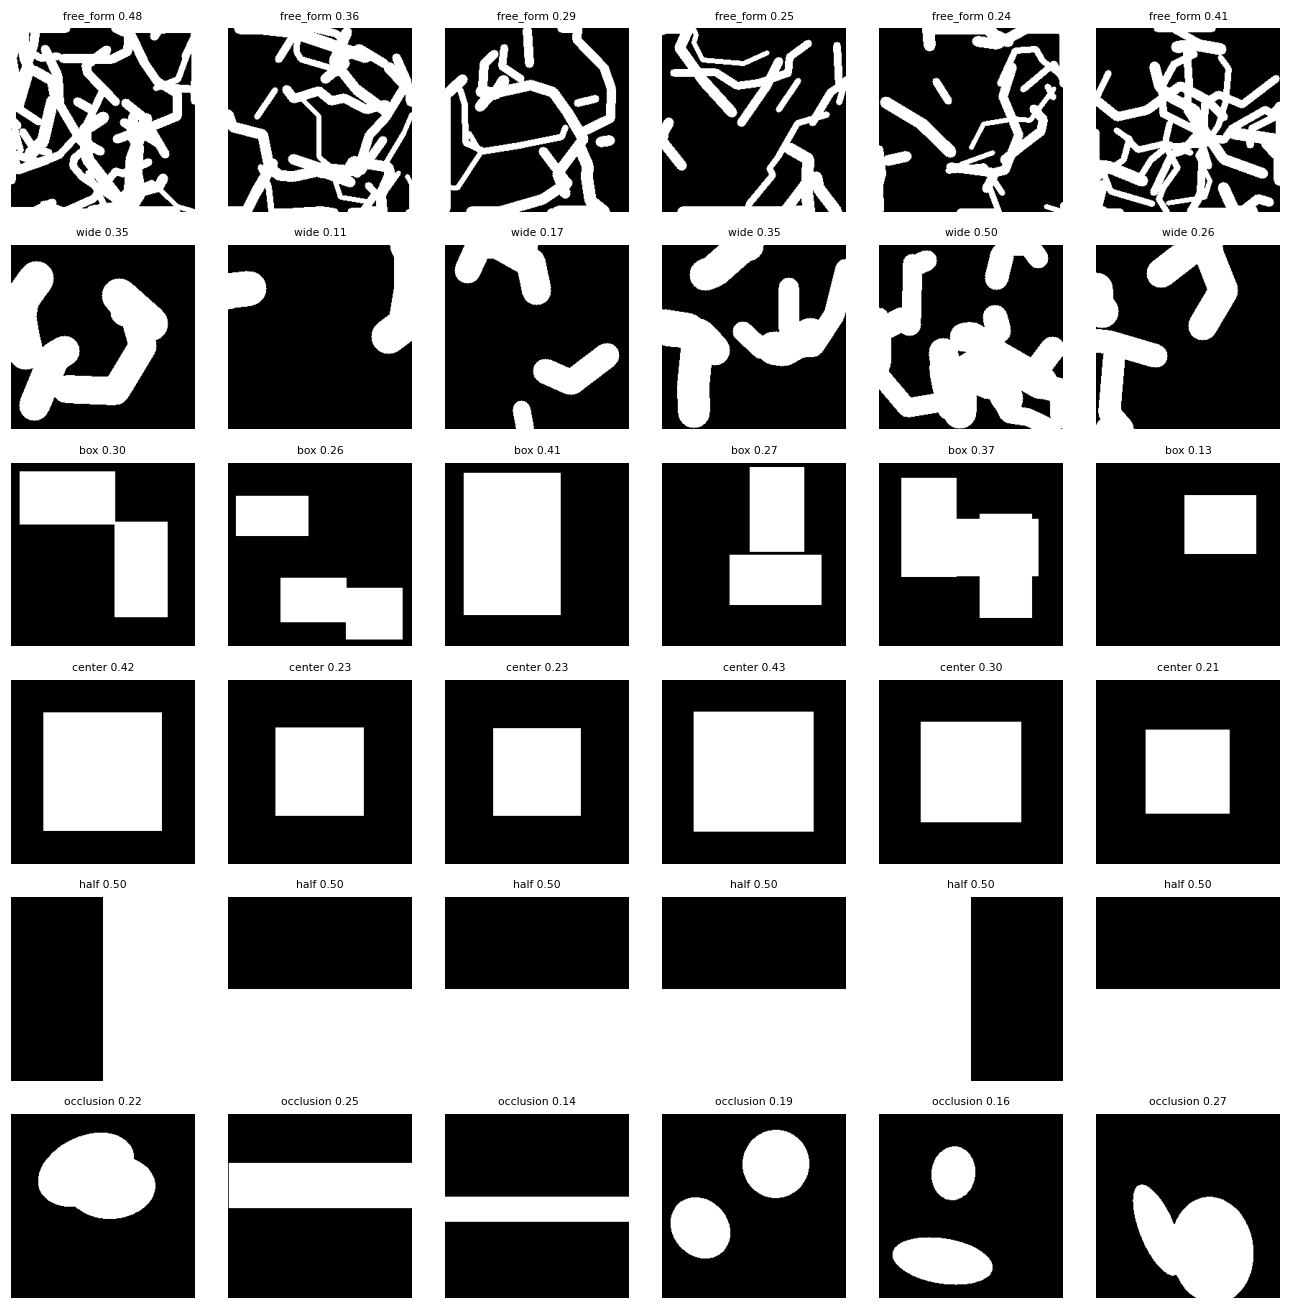

Hole-ratio histogram (0-0.1, 0.1-0.2, ..., 0.6-0.7): [  0 190 271 283 210  46   0]
Mean hole ratio: 0.31 | min: 0.10 | max: 0.50
Time per mask: 1.62 ms
Same seed gives the same mask: True
Two calls without seed differ: True


In [29]:
import time
import matplotlib.pyplot as plt

fig, axs = plt.subplots(len(MASK_TYPES), 6, figsize=(12, 12))
for i, t in enumerate(MASK_TYPES):
    for j in range(6):
        m = make_mask(mask_type=t)
        axs[i, j].imshow(m, cmap='gray', vmin=0, vmax=1)
        axs[i, j].axis('off')
        axs[i, j].set_title(f"{t} {m.mean():.2f}", fontsize=7)
plt.tight_layout()
plt.show()

ratios = np.array([make_mask().mean() for _ in range(1000)])
print("Hole-ratio histogram (0-0.1, 0.1-0.2, ..., 0.6-0.7):", np.histogram(ratios, bins=7, range=(0, 0.7))[0])
print(f"Mean hole ratio: {ratios.mean():.2f} | min: {ratios.min():.2f} | max: {ratios.max():.2f}")

t0 = time.time()
for _ in range(500):
    make_mask()
print(f"Time per mask: {(time.time() - t0) / 500 * 1000:.2f} ms")

a = make_mask(rng=np.random.default_rng(5))
b = make_mask(rng=np.random.default_rng(5))
print("Same seed gives the same mask:", np.array_equal(a, b))
print("Two calls without seed differ:", not np.array_equal(make_mask(), make_mask()))

### Use in training (dynamic masking)
`CelebAHQ256` from `dataset.py` calls `mask_fn(h, w)` for every sample, so passing `make_mask` is enough: each time an image is loaded it gets a new mask.

The cell below loads the same training image four times. The four masks should be different. The masked image shows holes as mid-gray because pixels are scaled to [-1, 1] and the hole value is 0.

Validation/test masks must be fixed so all models are compared on the same masks. That part is not included yet (it needs a small change in `dataset.py`).

In [30]:
# Create code/dataset.py so `from dataset import CelebAHQ256` works in the next cell (always rewritten with the latest version).
DATASET_PY = f'{BASE}/code/dataset.py'
DATASET_CODE = 'import os\nimport numpy as np\nimport torch\nfrom PIL import Image\nfrom torch.utils.data import Dataset\n\n\nclass CelebAHQ256(Dataset):\n    # fixed_masks=False -> new random mask on every load (training, dynamic masking)\n    # fixed_masks=True  -> same mask for the same image index every time (val/test)\n    def __init__(self, img_dir, split_file, augment=False, mask_fn=None, fixed_masks=False, mask_seed=42):\n        self.img_dir = img_dir\n        self.names = open(split_file).read().split()\n        self.augment = augment\n        self.mask_fn = mask_fn\n        self.fixed_masks = fixed_masks\n        self.mask_seed = mask_seed\n\n    def __len__(self):\n        return len(self.names)\n\n    def __getitem__(self, idx):\n        name = self.names[idx]\n        img = Image.open(os.path.join(self.img_dir, name)).convert("RGB")\n        img = np.asarray(img, dtype=np.float32) / 255.0\n        if self.augment and np.random.rand() < 0.5:\n            img = img[:, ::-1].copy()\n        # [0,1] -> [-1,1], shape (3, H, W)\n        image = torch.from_numpy(img).permute(2, 0, 1) * 2 - 1\n        h, w = image.shape[1:]\n        if self.fixed_masks:\n            mask_np = self.mask_fn(h, w, rng=np.random.default_rng(self.mask_seed + idx))\n        else:\n            mask_np = self.mask_fn(h, w)\n        mask = torch.from_numpy(mask_np).unsqueeze(0)   # (1, H, W), 1 = hole\n        masked = image * (1 - mask)\n        return {"image": image, "masked": masked, "mask": mask, "name": name}\n'
with open(DATASET_PY, 'w') as f:
    f.write(DATASET_CODE)
print('written:', DATASET_PY)


written: /content/drive/MyDrive/FYP_FaceCompletion/code/dataset.py


Train images: 3000
Sample keys and shapes: {'image': (3, 256, 256), 'masked': (3, 256, 256), 'mask': (1, 256, 256), 'name': '27224.png'}


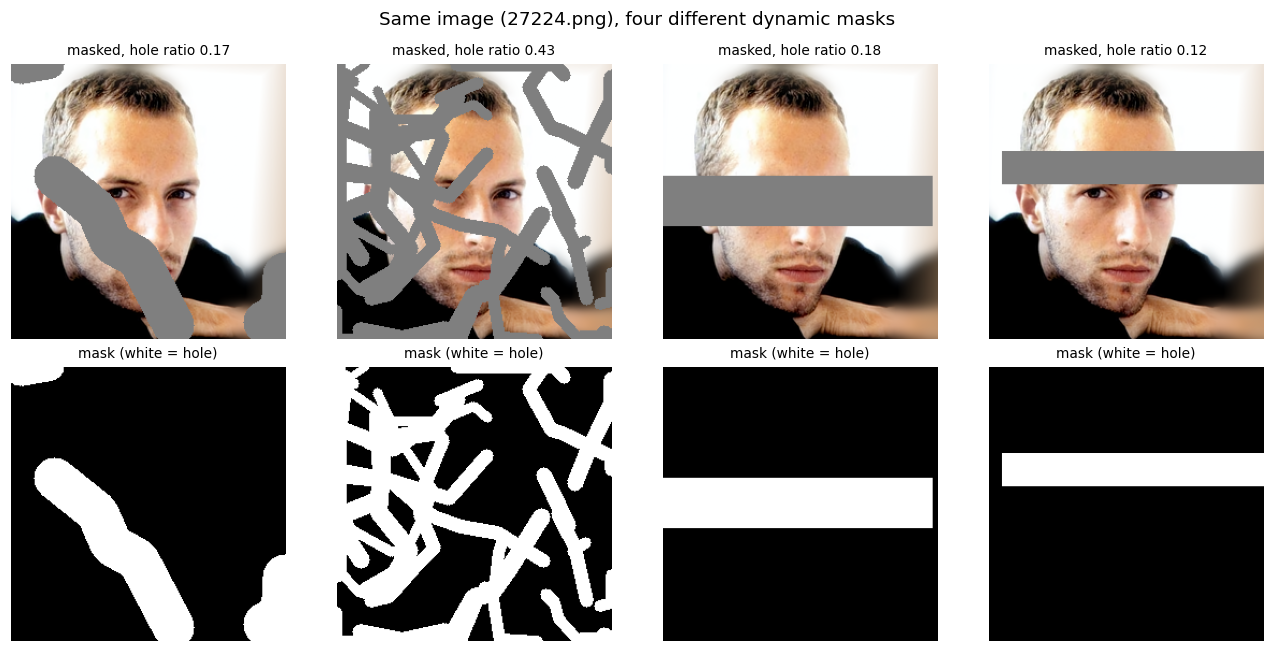

In [31]:
import sys
sys.path.insert(0, f'{BASE}/code')
from dataset import CelebAHQ256

train_set = CelebAHQ256(
    OUT,
    f'{ACTIVE_SPLIT_DIR}/train.txt',
    augment=False,
    mask_fn=make_mask
)
print("Train images:", len(train_set))

s = train_set[0]
print("Sample keys and shapes:", {k: (tuple(v.shape) if hasattr(v, 'shape') else v) for k, v in s.items()})

fig, axs = plt.subplots(2, 4, figsize=(12, 6))
for k in range(4):
    s = train_set[0]
    masked = ((s['masked'] + 1) / 2).permute(1, 2, 0).numpy()
    mask = s['mask'][0].numpy()
    axs[0, k].imshow(masked.clip(0, 1))
    axs[0, k].set_title(f"masked, hole ratio {mask.mean():.2f}", fontsize=9)
    axs[0, k].axis('off')
    axs[1, k].imshow(mask, cmap='gray', vmin=0, vmax=1)
    axs[1, k].set_title("mask (white = hole)", fontsize=9)
    axs[1, k].axis('off')
plt.suptitle(f"Same image ({s['name']}), four different dynamic masks")
plt.tight_layout()
plt.show()

In [32]:
IMG_DIR = "/content/celebahq256/all"
SPLIT_DIR = "/content/drive/MyDrive/FYP_FaceCompletion/splits_active"

train_dataset = CelebAHQ256(
    img_dir=IMG_DIR,
    split_file=f"{SPLIT_DIR}/train.txt",
    augment=True,
    mask_fn=make_mask,
    fixed_masks=False
)

val_dataset = CelebAHQ256(
    img_dir=IMG_DIR,
    split_file=f"{SPLIT_DIR}/val.txt",
    augment=False,
    mask_fn=make_mask,
    fixed_masks=True,
    mask_seed=42
)

test_dataset = CelebAHQ256(
    img_dir=IMG_DIR,
    split_file=f"{SPLIT_DIR}/test.txt",
    augment=False,
    mask_fn=make_mask,
    fixed_masks=True,
    mask_seed=42
)

In [33]:
train_dataset[0]

{'image': tensor([[[ 0.9529,  0.9608,  0.9686,  ...,  0.8745,  0.8667,  0.8588],
          [ 0.9529,  0.9686,  0.9686,  ...,  0.8745,  0.8667,  0.8588],
          [ 0.9529,  0.9686,  0.9686,  ...,  0.8745,  0.8667,  0.8588],
          ...,
          [-1.0000, -1.0000, -1.0000,  ...,  0.3804,  0.3882,  0.3961],
          [-1.0000, -1.0000, -1.0000,  ...,  0.3333,  0.3412,  0.3490],
          [-1.0000, -1.0000, -1.0000,  ...,  0.2863,  0.2941,  0.3020]],
 
         [[ 0.9765,  0.9843,  0.9843,  ...,  0.8039,  0.7882,  0.7804],
          [ 0.9765,  0.9843,  0.9843,  ...,  0.8039,  0.7882,  0.7804],
          [ 0.9765,  0.9843,  0.9843,  ...,  0.8039,  0.7882,  0.7804],
          ...,
          [-1.0000, -1.0000, -1.0000,  ...,  0.0745,  0.0745,  0.0824],
          [-1.0000, -1.0000, -1.0000,  ...,  0.0353,  0.0431,  0.0431],
          [-1.0000, -1.0000, -1.0000,  ..., -0.0039,  0.0039,  0.0118]],
 
         [[ 0.9922,  0.9922,  0.9922,  ...,  0.7333,  0.7176,  0.7020],
          [ 0.9922,

In [34]:
from torch.utils.data import DataLoader

In [35]:
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)